# Portfolio sintetico: riduzione single-pass

Il solve classico richiede CPLEX e una licenza utilizzabile. Se non disponibili, la failure reale e i risultati parziali restano visibili. La selezione MIS non è la soluzione finale.

In [1]:
import pandas as pd
from IPython.display import display

from qreduce.notebook_examples import portfolio_example
from qreduce.notebook_plots import plot_reduction_graph

example = portfolio_example()
result = example["result"]

## Grafo di input per la riduzione

I pesi sono i retention score assegnati agli asset; gli archi derivano dalla policy di correlazione. Il layout è illustrativo.


In [2]:
display(pd.DataFrame(example["nodes"]))
display(pd.DataFrame(example["edges"]))

,asset,retention_score
0,asset-a,0.9
1,asset-b,0.7
2,asset-c,0.6


,source,target,reason
0,asset-a,asset-b,abs_correlation=0.3 >= threshold=0.25


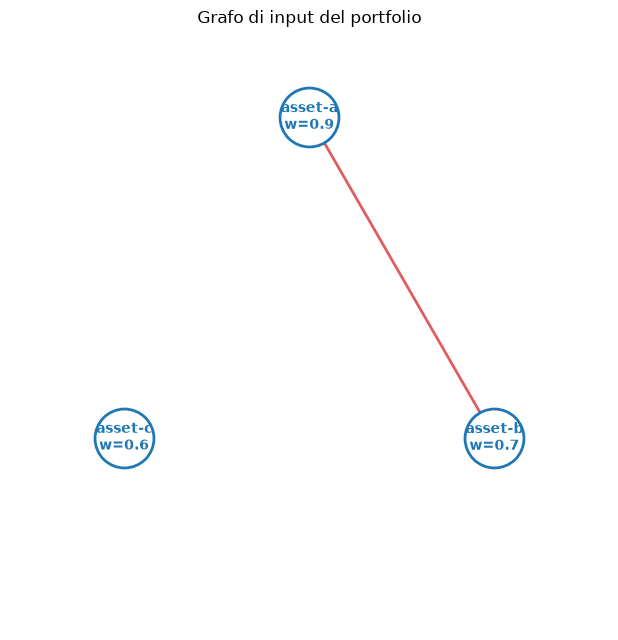

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plot_reduction_graph(example["graph"], title="Grafo di input del portfolio")
plt.show()

## Stato e diagnostica

In [4]:
display(pd.Series(result["run_result"], name="valore").to_frame())
display(pd.Series(result["metrics"], name="valore").to_frame())

,valore
run_id,notebook-portfolio
run_status,failed
stage,classical
terminal_reason,classical_backend_unavailable
classical_solver_status,unavailable
postcheck_status,not_run
adoption_status,not_adopted
round_results,[]
diagnostic_message,The optional CPLEX Python binding is not impor...
config_hash,b14e3a93bc1c3c05f966a79e51d7b811c3020d6417ca02...


,valore
best_bound,None
candidate_domain_size,2
classical_runtime_seconds,0.0
classical_solver_claimed_feasible,False
end_to_end_runtime_seconds,0.000367
mis_backend_family,classical_heuristic
mis_backend_id,greedy_mis
mis_compilation_runtime_seconds,0.000006
mis_device_id,None
mis_execution_mode,local


## Dominio mantenuto e fixing

Il verde rappresenta il dominio mantenuto quando disponibile, non la selezione finale del portfolio.


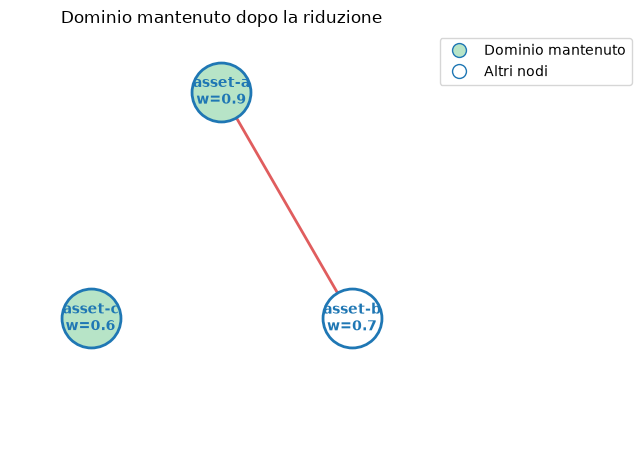

In [5]:
fig, ax = plot_reduction_graph(
    example["graph"], example["retained_ids"],
    highlighted_label="Dominio mantenuto", title="Dominio mantenuto dopo la riduzione",
)
plt.show()

In [6]:
display(pd.DataFrame(example["domain"]))
display(result["fixing_manifest"])

,asset,retained
0,asset-a,True
1,asset-b,False
2,asset-c,True


{'retained_item_ids': ['asset-a', 'asset-c'],
 'excluded_item_ids': ['asset-b'],
 'entries': [{'item_id': 'asset-b',
   'variable_values': {'delta__asset-b': 0.0, 'x__asset-b': 0.0},
   'reason': 'heuristic_candidate_domain_exclusion'}],
 'origin': 'heuristic_candidate_domain',
 'provenance': {'graph_policy_id': 'notebook-policy',
  'graph_policy_version': '1',
  'optimality_preservation_claim': 'none'}}

## Campioni MIS e risultato classico

In [7]:
display(pd.DataFrame(result["selected_mis_samples"]))
display(result["classical_result"])
display(result["postcheck_result"])

,raw_sample_id,node_order,delta,occurrence_count,backend_reported_score,backend_reported_score_kind,canonical_qubo_energy,canonical_ising_energy,selection_weight,num_selected,is_independent_set,violated_edges,num_violated_edges,source_provider_id,source_backend_id,execution_runtime_seconds,effective_compilation_parameters,effective_execution_parameters,raw_backend_metadata,source_raw_sample_ids
0,notebook-portfolio:round:0:local-greedy:sample...,"[asset-a, asset-b, asset-c]","[1, 0, 1]",1,None,unavailable,-1.5,-1.5,1.5,2,True,[],0,local,greedy_mis,0.000023,{},{},{'algorithm': 'seeded_greedy_independent_set'},[notebook-portfolio:round:0:local-greedy:sampl...


{'classical_solver_status': 'unavailable',
 'terminal_reason': 'classical_backend_unavailable',
 'solver_claimed_feasible': False,
 'objective_value': None,
 'best_bound': None,
 'gap': None,
 'is_optimal': False,
 'is_time_limited': False,
 'runtime_seconds': 0.0,
 'variable_values': {},
 'variable_count': None,
 'constraint_count': None,
 'effective_solver_parameters': {},
 'model_export_path': None,
 'remaining_time_budget_at_start_seconds': 59.999730624986114,
 'diagnostic_message': 'The optional CPLEX Python binding is not importable.',
 'requested_solver_id': 'cplex',
 'effective_solver_id': None}

None